# Mean-performance numbers: is the mean degraded by the uncertainty heads? (pr_classic3)

REPORTING notebook: it produces the numbers to quote, not figures. Deliberately light on markdown (the logic lives in `src/evaluation/benchmark_summary.py`). Same structure as the other canal 1 reporting notebooks, same `msemeanonly` baseline, same machinery.

**log1p(CP10k) axis only**: the `*_raw` models are excluded (log1p(raw counts) axis, separate table). beta-NLL sweep reduced to `lambda = 0.0` (the proper NLL). Both estimators are reported: **B** = `pearson` = `g*` (predictive mean of the transform) and **A** = `pearson_logmean` = `log1p(mu/delta)` (mean only) -- count models only.

## What `pr_classic3` contributes

1. **The `g*` truncation anchored on the NB mode**, so the exact truncated sum stops early, and gene blocks ordered so a block is not priced by the single worst cell of the whole panel. Per-gene correlation with the unanchored `g*` is 1 - 3.5e-12, i.e. the same number computed faster.
2. **The `msemeanonly` baseline is part of the sweep itself**, so every delta below is computed against a baseline trained under exactly the same conditions. 10 model types over the three cohorts.
3. **A third independent pass of the same sweep.** Three independent trainings measure the retraining variance directly, and so which published statements are stable. Point estimates reproduce to ~0.001, while universal quantifiers ("at every cutoff", "never", an unrestricted "marginally better") do not.


In [11]:
import sys
import importlib
from pathlib import Path
import numpy as np
import pandas as pd

PROJ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.append(str(PROJ))   # parent dir of src (notebooks are not pip-installed on the cluster)

# benchmark_summary.py is edited alongside this notebook, and a kernel that already imported it
# keeps the module object cached, so a new function would stay invisible and raise NameError.
# Reloading here makes re-running this cell enough; no kernel restart needed.
import src.evaluation.benchmark_summary as bs
importlib.reload(bs)
from src.evaluation.benchmark_summary import (
    discover_run_summaries, headline_registry, format_headline_registry,
    cutoff_donor_points, paired_donor_deltas, paired_deltas_full, estimator_gap,
    REGISTRY_METRICS,
)

RUN_ID    = "pr_classic3"
DATASETS  = ["10x_TuPro", "TLS", "LUNG_CANCER"]
RADIUS    = "r75"
REFERENCE = "msemeanonly"                      # the mean-only baseline the section argues against
NS        = [50, 100, 500, 1000, 2000, None]   # None -> the full shared panel
METRICS   = ("pearson", "pearson_logmean")     # B, then A (A exists for count models only)

# log1p(CP10k) axis ONLY. The depth-blind *_raw pair reports on log1p(raw counts) and must never
# share a table or an axis with these; it gets its own report block when needed.
# The last two exist under pr_classic1 as well, so both runs carry them and the
#          comparison IS available.
CP_MODELS = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
             "poisson_cp", "negativebinomial_hetero_noanchor_cp",
             "negativebinomial_spotdisp_cp", "negativebinomial_genedisp_cp"]

summaries = discover_run_summaries(PROJ / "results", RUN_ID, DATASETS,
                                   radius=RADIUS, models=CP_MODELS, lambda_keep=0.0)
print(f"{len(summaries)} runs loaded")
for s in summaries:
    print(f"   {s['dataset']:<12s} {s['label']}")

# Without the baseline every delta cell below silently produces empty tables, so fail here
# instead -- most likely cause is that canal1 has not yet written benchmark_summary.parquet.
_found = {s["label"].split("|")[0] for s in summaries}
assert REFERENCE in _found, (
    f"reference {REFERENCE!r} missing from the loaded runs ({sorted(_found)}). "
    f"has canal1 run on that model?")
_missing = [m for m in CP_MODELS if m not in _found]
if _missing:
    print(f"\n(!) models requested but not found: {_missing}")

24 runs loaded
   10x_TuPro    heteroscedastic|lam0.0
   10x_TuPro    homoscedastic|lam0.0
   10x_TuPro    msemeanonly
   10x_TuPro    negativebinomial_genedisp_cp
   10x_TuPro    negativebinomial_hetero_noanchor_cp
   10x_TuPro    negativebinomial_spotdisp_cp
   10x_TuPro    poisson_cp
   10x_TuPro    spot_homoscedastic|lam0.0
   TLS          heteroscedastic|lam0.0
   TLS          homoscedastic|lam0.0
   TLS          msemeanonly
   TLS          negativebinomial_genedisp_cp
   TLS          negativebinomial_hetero_noanchor_cp
   TLS          negativebinomial_spotdisp_cp
   TLS          poisson_cp
   TLS          spot_homoscedastic|lam0.0
   LUNG_CANCER  heteroscedastic|lam0.0
   LUNG_CANCER  homoscedastic|lam0.0
   LUNG_CANCER  msemeanonly
   LUNG_CANCER  negativebinomial_genedisp_cp
   LUNG_CANCER  negativebinomial_hetero_noanchor_cp
   LUNG_CANCER  negativebinomial_spotdisp_cp
   LUNG_CANCER  poisson_cp
   LUNG_CANCER  spot_homoscedastic|lam0.0


In [12]:
# Headline: full shared gene panel, every available uncertainty + the K raw per-donor points.
# The COMPLETE registry rather than just the two correlation estimators: disp_signed / ece_pit /
# var_residual_corr are already in it, and the last cell needs disp_signed for the two new heads.
stats_headline, donor_points = headline_registry(summaries, metrics=REGISTRY_METRICS)
print(format_headline_registry(stats_headline, datasets=DATASETS, metrics=REGISTRY_METRICS))

for ds in DATASETS:
    sub = donor_points[(donor_points["dataset"] == ds) & (donor_points["metric"] == "pearson")]
    if not sub.empty:
        print(f"\n-- per-donor points (B), {ds} --")
        print(sub.pivot_table(index="model", columns="donor", values="value").round(4).to_string())

HEADLINE -- full shared gene panel. THREE DIFFERENT THINGS, do not swap them:
  SE / t-CI     spread of the MEAN over donors (patients resampled, gene panel fixed).
                One estimand, two presentations: t-CI = mean +/- t*·SE.  <- THE headline bar.
  PI-new-donor  where a NEW patient would land. Wider, and a different question entirely.
  gene-boot     genes resampled, donor cohort FIXED -> ZERO inter-donor variance.
                Gene-panel stability only; far narrower (N genes vs K donors).
LOPO folds share K-2 training donors (Bengio & Grandvalet 2004), so these intervals are
optimistic -- always read them next to the per-donor points (donor_points).

--- 10x_TuPro | pearson  (K=7 donors, N=3000 genes) ---
  spot_homoscedastic|lam0.0                  +0.1752  SE 0.0134  t-CI [+0.1425,+0.2079] (df 6, t* 2.45)  PI-new-donor [+0.0826,+0.2678]  gene-boot [+0.1705,+0.1798] (SE 0.0024)
  homoscedastic|lam0.0                       +0.1744  SE 0.0134  t-CI [+0.1416,+0.2072] (df 

In [13]:
# Paired deltas vs the baseline: ALL cutoffs, THREE uncertainty readings.
# D = mat_model - mat_reference (genes x donors) is built ONCE per (model, metric, cutoff) and then
# collapsed either way, so the three readings describe the SAME quantity (identical point estimate)
# and differ only in what is resampled:
#   t-CI / SEM  collapse over GENES  -> K donor deltas -> patients resampled  <- THE headline bar
#   boot-gene   collapse over DONORS -> N gene deltas  -> genes resampled, donor cohort FIXED
# NOTE: only metric B appears here. A = pearson_logmean exists for COUNT models only, so a delta in
# A against the mean-only baseline is UNDEFINED (the baseline has no A). The A-vs-B question is the
# within-model Jensen gap, computed two cells down.
deltas = paired_deltas_full(summaries, reference=REFERENCE, metrics=METRICS, ns=NS)
print(f"{len(deltas)} deltas (dataset x metric x cutoff x model)")

LABEL = {"pearson": "B = g* = E[log1p(Y/delta)]", "pearson_logmean": "A = log1p(mu/delta), mean-only"}

for ds in DATASETS:
    for m in METRICS:
        sub = deltas[(deltas["dataset"] == ds) & (deltas["metric"] == m)]
        if sub.empty:
            continue
        print(f"\n=== {ds} | {LABEL[m]} | delta vs {REFERENCE} ===")
        base = sub.drop_duplicates("n").set_index("n")["reference_mean"]
        print("   base :  " + "   ".join(f"n={int(k)}: {v:+.4f}" for k, v in base.items()))

        # (a) the effect. '*' = donor Student-t CI excludes 0 (the claim that matters);
        #     'o' = gene-bootstrap CI excludes 0 (gene-panel stable, says nothing about a new patient).
        cells = [f"{r.delta_mean:+.4f}{'*' if r.excludes_zero_t else ' '}"
                 f"{'o' if r.excludes_zero_gene else ' '}" for r in sub.itertuples()]
        print(sub.assign(c=cells).pivot_table(index="model", columns="n",
                                              values="c", aggfunc="first").to_string())

        # (b) the three half-widths side by side: t-CI / 1 SEM / gene-bootstrap.
        w = [f"{(r.delta_ci_hi - r.delta_ci_lo) / 2:.4f}/{r.delta_sem:.4f}/"
             f"{(r.gene_ci_hi - r.gene_ci_lo) / 2:.4f}" for r in sub.itertuples()]
        print("\n   half-widths  t-CI / SEM / boot-gene :")
        print(sub.assign(c=w).pivot_table(index="model", columns="n",
                                          values="c", aggfunc="first").to_string())

126 deltas (dataset x metric x cutoff x model)

=== 10x_TuPro | B = g* = E[log1p(Y/delta)] | delta vs msemeanonly ===
   base :  n=50: +0.5471   n=100: +0.5075   n=500: +0.3892   n=1000: +0.3258   n=2000: +0.2412   n=3000: +0.1721
n                                         50         100        500        1000       2000       3000
model                                                                                                
heteroscedastic|lam0.0               +0.0052 o  +0.0038 o  +0.0033 o  +0.0033*o  +0.0025 o  +0.0020 o
homoscedastic|lam0.0                 +0.0024*o  +0.0030 o  +0.0028 o  +0.0029 o  +0.0027 o  +0.0023 o
negativebinomial_genedisp_cp         -0.0164*o  -0.0132*o  -0.0075 o  -0.0077 o  -0.0110*o  -0.0095*o
negativebinomial_hetero_noanchor_cp  -0.0059 o  -0.0072 o  -0.0126*o  -0.0126*o  -0.0105*o  -0.0066*o
negativebinomial_spotdisp_cp         -0.0510*o  -0.0433*o  -0.0292*o  -0.0220*o  -0.0165*o  -0.0116*o
poisson_cp                           -0.0085 o  -0.0059

In [14]:
# The DETECTED effects only -- the ones a sentence in the paper may name.
hits = deltas[deltas["excludes_zero_t"]].sort_values(["dataset", "n", "delta_mean"])
print(f"=== DETECTED effects: donor CI on the difference excludes 0  ({len(hits)} / {len(deltas)}) ===")
for r in hits.itertuples():
    print(f"{r.dataset:<12s} n={r.n:<5d} {r.model:<40s} "
          f"delta {r.delta_mean:+.4f} [{r.delta_ci_lo:+.4f},{r.delta_ci_hi:+.4f}]  "
          f"donors {r.n_donors_better}+/{r.n_donors_worse}-")

# Equivalence bound PER CUTOFF. Reporting a single bound over all cutoffs would be dominated by
# n=50, where the CIs are widest (few genes) -- that says "we cannot see anything at n=50", not
# "the models are equivalent". The bound only means something at a stated n.
print("\n=== equivalence bound per cutoff (worst CI lower bound, models NOT detected) ===")
safe = deltas[~deltas["excludes_zero_t"]]
for ds in DATASETS:
    g_ds = safe[safe["dataset"] == ds]
    if g_ds.empty:
        continue
    parts = []
    for n, g in g_ds.groupby("n", sort=True):
        w = g.loc[g["delta_ci_lo"].idxmin()]
        parts.append(f"n={int(n)}: {w['delta_ci_lo']:+.4f}")
    print(f"{ds:<12s} " + "   ".join(parts))

# Which models are never detected anywhere: the clean equivalence claims.
print("\n=== models never detected (equivalent to the baseline at every cutoff) ===")
for ds in DATASETS:
    d_ds = deltas[deltas["dataset"] == ds]
    never = sorted(set(d_ds["model"]) - set(d_ds[d_ds["excludes_zero_t"]]["model"]))
    print(f"{ds:<12s} {', '.join(never) if never else '(none)'}")

=== DETECTED effects: donor CI on the difference excludes 0  (56 / 126) ===
10x_TuPro    n=50    negativebinomial_spotdisp_cp             delta -0.0510 [-0.0827,-0.0194]  donors 0+/7-
10x_TuPro    n=50    negativebinomial_genedisp_cp             delta -0.0164 [-0.0287,-0.0041]  donors 1+/6-
10x_TuPro    n=50    homoscedastic|lam0.0                     delta +0.0024 [+0.0002,+0.0046]  donors 6+/1-
10x_TuPro    n=100   negativebinomial_spotdisp_cp             delta -0.0433 [-0.0704,-0.0162]  donors 0+/7-
10x_TuPro    n=100   negativebinomial_genedisp_cp             delta -0.0132 [-0.0241,-0.0024]  donors 1+/6-
10x_TuPro    n=500   negativebinomial_spotdisp_cp             delta -0.0292 [-0.0461,-0.0123]  donors 0+/7-
10x_TuPro    n=500   negativebinomial_hetero_noanchor_cp      delta -0.0126 [-0.0185,-0.0068]  donors 0+/7-
10x_TuPro    n=500   spot_homoscedastic|lam0.0                delta +0.0039 [+0.0007,+0.0072]  donors 6+/1-
10x_TuPro    n=1000  negativebinomial_spotdisp_cp           

In [15]:
# A vs B: the JENSEN GAP, within each count model (the only place A is defined).
# gap = B - A per (gene, donor), collapsed the same two ways. Positive = routing the prediction
# through the full fitted predictive (mu AND alpha) beats using the mean alone.
from src.evaluation.benchmark_summary import estimator_gap

gaps = estimator_gap(summaries, metric_b="pearson", metric_a="pearson_logmean", ns=NS)
print(f"{len(gaps)} gaps (dataset x cutoff x count model)\n")

for ds in DATASETS:
    sub = gaps[gaps["dataset"] == ds]
    if sub.empty:
        continue
    print(f"=== {ds} | gap B - A ('*' donor CI excludes 0, 'o' gene bootstrap excludes 0) ===")
    cells = [f"{r.gap_mean:+.4f}{'*' if r.excludes_zero_t else ' '}"
             f"{'o' if r.excludes_zero_gene else ' '}" for r in sub.itertuples()]
    print(sub.assign(c=cells).pivot_table(index="model", columns="n",
                                          values="c", aggfunc="first").to_string())
    w = [f"{(r.gap_ci_hi - r.gap_ci_lo) / 2:.4f}/{r.gap_sem:.4f}/"
         f"{(r.gene_ci_hi - r.gene_ci_lo) / 2:.4f}" for r in sub.itertuples()]
    print("\n   half-widths  t-CI / SEM / boot-gene :")
    print(sub.assign(c=w).pivot_table(index="model", columns="n",
                                      values="c", aggfunc="first").to_string())
    print()

72 gaps (dataset x cutoff x count model)

=== 10x_TuPro | gap B - A ('*' donor CI excludes 0, 'o' gene bootstrap excludes 0) ===
n                                         50         100        500        1000       2000       3000
model                                                                                                
negativebinomial_genedisp_cp         +0.0002    +0.0001    +0.0000    -0.0001 o  -0.0001 o  -0.0001 o
negativebinomial_hetero_noanchor_cp  +0.0052 o  +0.0018    -0.0046 o  -0.0039 o  +0.0023 o  +0.0046 o
negativebinomial_spotdisp_cp         -0.0328*o  -0.0280*o  -0.0178 o  -0.0109 o  -0.0001    +0.0030 o
poisson_cp                           +0.0002*o  +0.0002*o  +0.0002*o  +0.0001 o  -0.0000    -0.0000  

   half-widths  t-CI / SEM / boot-gene :
n                                                    50                    100                   500                   1000                  2000                  3000
model                                            

wrote: fig_mean_performance_pr_classic3.pdf


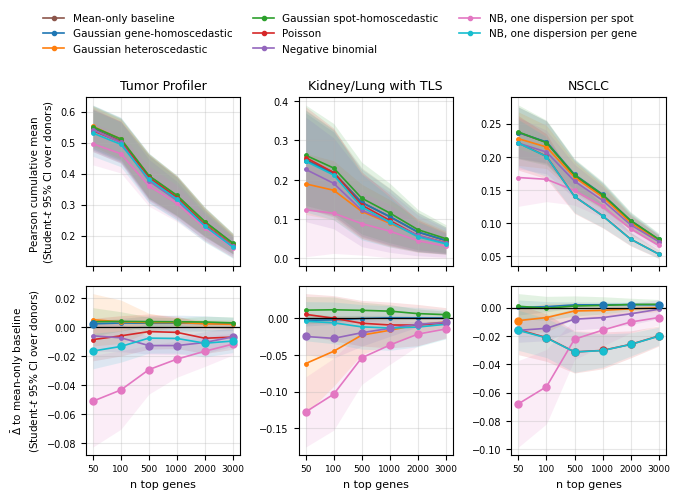

In [16]:
# FIGURE fig:mean-performance -- 2 rows x 3 datasets.
#   top    absolute cumulative Pearson (B), donor Student-t 95% CI
#   bottom PAIRED delta vs the mean-only baseline, same CI family
# The bottom row exists because on the top row the curves are visually superimposed: the effects
# discussed in the text (0.005-0.036) are invisible at a 0-0.55 scale. The baseline IS the zero
# line below, so nothing is lost by dropping it from that row.
#
# SIZED FOR A PORTRAIT PAGE. Drawn at roughly its printed size (~6.9 in for a ~6.3 in textwidth),
# NOT larger: a wide figure shrunk by \includegraphics[width=\textwidth] has its fonts shrunk by
# the same factor and becomes unreadable. The legend sits ABOVE rather than beside, because in
# portrait the scarce resource is width, not height; and there is no suptitle, which would only
# duplicate the LaTeX caption.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from src.evaluation.benchmark_summary import donor_lopo_stats

# Canonical model -> color map, keyed on model_type (NOT the |lam label): a positional scheme
# silently recolors a model when the loaded set changes.
# The six from pr_classic1 keep their colors EXACTLY. The two restricted-dispersion NB heads are
# take the next free tab10 slots (C6 pink, C9 cyan), so no model ever wears two colors across the
# report.
MODEL_COLORS = {
    "msemeanonly":                         "#8c564b",   # brown  -- the mean-only baseline
    "homoscedastic":                       "#1f77b4",   # blue
    "heteroscedastic":                     "#ff7f0e",   # orange
    "spot_homoscedastic":                  "#2ca02c",   # green
    "poisson_cp":                          "#d62728",   # red    -- Poisson family
    "negativebinomial_hetero_noanchor_cp": "#9467bd",   # purple -- NB family, free dispersion
    "negativebinomial_spotdisp_cp":        "#e377c2",   # pink   -- NB, one dispersion per spot
    "negativebinomial_genedisp_cp":        "#17becf",   # cyan   -- NB, one dispersion per gene
}
# Display names. The internal model_type carries implementation detail (_cp, _hetero_noanchor,
# |lam0.0) that means nothing to a reader; these match the wording of the overview section.
# Note: the two restricted-dispersion heads are NOT the count analogues of the
# Gaussian homoscedastic / spot-homoscedastic heads. Constraining the dispersion does not make the
# predictive variance constant -- NB var = mu + alpha*mu^2 still varies through mu -- so they
# restrict WHERE the overdispersion may come from, not whether the variance is input-dependent.
MODEL_LABELS = {
    "msemeanonly":                         "Mean-only baseline",
    "homoscedastic":                       "Gaussian gene-homoscedastic",
    "heteroscedastic":                     "Gaussian heteroscedastic",
    "spot_homoscedastic":                  "Gaussian spot-homoscedastic",
    "poisson_cp":                          "Poisson",
    "negativebinomial_hetero_noanchor_cp": "Negative binomial",
    "negativebinomial_spotdisp_cp":        "NB, one dispersion per spot",
    "negativebinomial_genedisp_cp":        "NB, one dispersion per gene",
}
MODEL_ORDER = ["msemeanonly", "homoscedastic", "heteroscedastic", "spot_homoscedastic",
               "poisson_cp", "negativebinomial_hetero_noanchor_cp",
               "negativebinomial_spotdisp_cp", "negativebinomial_genedisp_cp"]
DATASET_LABELS = {"10x_TuPro":   "Tumor Profiler",
                  "TLS":         "Kidney/Lung with TLS",
                  "LUNG_CANCER": "NSCLC"}

def _mt(label): return label.split("|")[0]

# Top row: per-model cumulative curve + donor t-CI. Rebuilt from cutoff_donor_points, which applies
# the SAME gene ordering as paired_deltas_full, so the two rows of the figure cannot drift apart.
points = cutoff_donor_points(summaries, ns=NS, metrics=("pearson",))
rows = []
for (ds, model, n), g in points.groupby(["dataset", "model", "n"]):
    st = donor_lopo_stats(dict(zip(g["donor"], g["value"])))
    rows.append(dict(dataset=ds, model=model, n=n, mean=st["mean"],
                     lo=st["ci95_mean"][0], hi=st["ci95_mean"][1]))
curves = pd.DataFrame(rows)

NS_PLOT = sorted(curves["n"].unique())
x = np.arange(len(NS_PLOT))
fig, axes = plt.subplots(2, len(DATASETS), figsize=(6.9, 5.0), sharex=True)

for j, ds in enumerate(DATASETS):
    top, bot = axes[0, j], axes[1, j]
    present = set(curves.loc[curves["dataset"] == ds, "model"])
    for mt in MODEL_ORDER:                                   # fixed order -> stable colors/legend
        model = next((m for m in present if _mt(m) == mt), None)
        if model is None:
            continue
        c = MODEL_COLORS[mt]
        cur = (curves[(curves["dataset"] == ds) & (curves["model"] == model)]
               .set_index("n").reindex(NS_PLOT))
        top.fill_between(x, cur["lo"], cur["hi"], color=c, alpha=0.13, linewidth=0)
        top.plot(x, cur["mean"], "-o", ms=2.5, lw=1.2, color=c)

        d = deltas[(deltas["dataset"] == ds) & (deltas["metric"] == "pearson")
                   & (deltas["model"] == model)]
        if d.empty:
            continue                      # the reference itself: it IS the zero line below
        d = d.set_index("n").reindex(NS_PLOT)
        bot.fill_between(x, d["delta_ci_lo"], d["delta_ci_hi"], color=c, alpha=0.13, linewidth=0)
        bot.plot(x, d["delta_mean"], "-o", ms=2.5, lw=1.2, color=c)
        # filled larger marker where the donor CI excludes 0 (the only points the text names)
        det = d["excludes_zero_t"].fillna(False).to_numpy().astype(bool)
        bot.plot(x[det], d["delta_mean"].to_numpy()[det], "o", ms=5, color=c, zorder=5)

    bot.axhline(0, color="black", lw=0.9)
    top.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    for ax in (top, bot):
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
    bot.set_xticks(x)
    bot.set_xticklabels([str(n) for n in NS_PLOT], fontsize=6.5)
    bot.set_xlabel("n top genes", fontsize=8)

axes[0, 0].set_ylabel("Pearson cumulative mean \n(Student-$t$ 95% CI over donors)",
                      fontsize=7.5)
axes[1, 0].set_ylabel("$\\bar{\\Delta}$ to mean-only baseline\n(Student-$t$ 95% CI over donors)",
                      fontsize=7.5)

handles = [Line2D([0], [0], color=MODEL_COLORS[mt], marker="o", ms=3, lw=1.2,
                  label=MODEL_LABELS[mt]) for mt in MODEL_ORDER]
plt.tight_layout(rect=[0, 0, 1, 0.88])
fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.0),
           ncol=3, frameon=False, fontsize=7.5)

# DISTINCT filename per run, so re-running one notebook can never overwrite another run's figure.
FIG_DIR = PROJ / "results" / "_analysis" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_mean_performance_pr_classic3.{ext}", dpi=300, bbox_inches="tight")
print("wrote:", "fig_mean_performance_pr_classic3.pdf")
plt.show()

gene_expression_stats_per_donor : 332,162 rows (dataset, donor, gene)
  10x_TuPro    16,500 genes x 7 donors
  TLS          17,845 genes x 6 donors
  LUNG_CANCER  13,699 genes x 8 donors

written: fig_expression_topn_pr_classic3.pdf


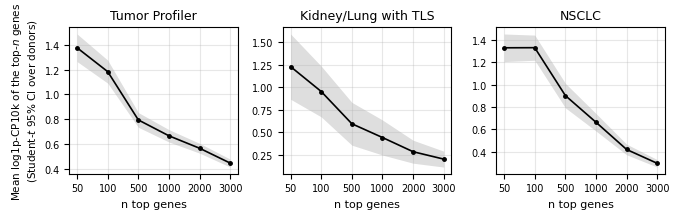


=== cumulative mean expression of the top n genes, log1p-CP10k [95% donor CI on the mean] ===
n                               50                       100                      500                      1000                     2000                     3000
dataset                                                                                                                                                          
10x_TuPro    1.3761 [1.2647, 1.4874]  1.1834 [1.0905, 1.2763]  0.7937 [0.7343, 0.8532]  0.6655 [0.6155, 0.7155]  0.5653 [0.5259, 0.6047]  0.4454 [0.4134, 0.4774]
TLS          1.2278 [0.8652, 1.5905]  0.9514 [0.6693, 1.2335]  0.5930 [0.3551, 0.8308]  0.4401 [0.2454, 0.6348]  0.2823 [0.1546, 0.4100]  0.2001 [0.1117, 0.2886]
LUNG_CANCER  1.3308 [1.2070, 1.4545]  1.3318 [1.2190, 1.4447]  0.9025 [0.7927, 1.0122]  0.6633 [0.5848, 0.7418]  0.4194 [0.3717, 0.4671]  0.2952 [0.2617, 0.3286]

   inter-donor sd / sem (K donors):
n                     50             100            500   

In [17]:
# =====================================================================================================
# FIGURE fig:expression_topn -- mean gene expression, 1 row x 3 datasets. A SEPARATE figure, on
# purpose: the figure above is the one the paper includes, and it is left untouched.
#
# Same quantity as the LAST row of Figure 4 in
# the exploratory canal 1 notebook, laid out for the paper: there one figure
# per dataset (4 stacked panels), here the 3 datasets SIDE BY SIDE on a single row.
#
# What the curve shows: the cumulative mean expression of the SAME top-n gene sets the figure
# above scores, so the two read along the same x axis -- "are the best-predicted genes also the
# most expressed?". It is a property of the DATA (no model, no prediction): one black curve per
# dataset, no model color.
#
# Scale = log1p-CP10k (mean_log1p_cp10k), NOT raw CP10k: raw CP10k is heavily right-skewed
# (TuPro, nonzero values: max 4211 against p99 12.66), and a Student interval is symmetric by
# construction, so it would place both of its bounds badly there.
# It is also the axis the models' Pearson is computed on: one scale for both
# figures.
#
# The band is the SAME family as above (Student-t 95% over the K per-donor points). Under LOPO
# each donor is the test donor exactly once and ALL of its spots form the test split of that
# fold, so "every spot of donor d" and "the test spots of donor d" are the same
# set: the per-donor expression means line up with the models' per-donor points
# with no population shift to justify. A DESCRIPTIVE interval (how much the expression level
# varies between patients), never a claim about a model generalizing.
#
# Depends on the figure cell above for DATASET_LABELS and FIG_DIR.
# =====================================================================================================
import matplotlib.pyplot as plt
from src.evaluation.benchmark_summary import gene_donor_matrix, donor_lopo_stats

# Per-gene expression stats, MODEL-INDEPENDENT, precomputed on the cluster by
# snake/scripts/canals/dataset_gene_expression_stats_precompute.py (reads the merged v5/r75
# adata of each dataset only once). Two groupings are written; it is the PER-DONOR version
# that is needed here, because a Student interval needs K points per donor and the
# dataset-wide table collapses them into a single number per gene. It lives in the SHARED tree
# results/_analysis (a property of the data, not a run output), NOT under the pr_classic3 run directory.
GENE_EXPR_DONOR_PARQUET = PROJ / "results" / "_analysis" / "gene_expression_stats_per_donor.parquet"
assert GENE_EXPR_DONOR_PARQUET.is_file(), (
    f"absent : {GENE_EXPR_DONOR_PARQUET}\n"
    "-> a single CPU job, model-independent: "
    "bash snake/scripts/canals/launch_dataset_gene_expression_stats_precompute.sh")

expr_donor_df = pd.read_parquet(GENE_EXPR_DONOR_PARQUET)
EXPR_DONOR_BY_DS = {ds: g.pivot_table(index="gene", columns="donor", values="mean_log1p_cp10k")
                    for ds, g in expr_donor_df.groupby("dataset")}
print(f"gene_expression_stats_per_donor : {len(expr_donor_df):,} rows (dataset, donor, gene)")
for ds in DATASETS:
    m = EXPR_DONOR_BY_DS.get(ds)
    print(f"  {ds:<12s} " + ("(absent)" if m is None else
                             f"{m.shape[0]:,} genes x {m.shape[1]} donors"))


def shared_gene_order(ds):
    """The gene ranking of the figure above, rebuilt here.

    cutoff_donor_points / paired_deltas_full rebuild it internally and do not return it, so
    these few lines replicate it identically: the gene set SHARED by the loaded models,
    ranked by Pearson averaged over the donors then across models, descending. Without
    that, "n = 500" would not designate the same 500 genes on the two figures.
    """
    group = [s for s in summaries if s["dataset"] == ds]
    assert len({s["gene_set"] for s in group}) == 1, f"{ds} : several gene_sets, ambiguous order"
    shared, pieces = None, []
    for s in group:
        mat = gene_donor_matrix(s["per_long"], "pearson")
        shared = set(mat.index) if shared is None else (shared & set(mat.index))
        pieces.append(mat.mean(axis=1))
    shared = sorted(shared)
    return pd.concat(pieces, axis=1).loc[shared].mean(axis=1).sort_values(ascending=False).index


rows = []
for ds in DATASETS:
    order = shared_gene_order(ds)
    mat = EXPR_DONOR_BY_DS[ds].reindex(order)      # (gene x donor), in the curve order
    n_missing = int(mat.isna().all(axis=1).sum())
    if n_missing:
        print(f"(!) {ds} : {n_missing}/{len(order)} panel genes missing from the expression parquet")
    for n in sorted({len(order) if k is None else min(int(k), len(order)) for k in NS}):
        st = donor_lopo_stats(mat.iloc[:n].mean(axis=0, skipna=True).to_dict())  # genes -> K points
        rows.append(dict(dataset=ds, n=int(n), K=st["K"], mean=st["mean"], sd=st["sd"],
                         sem=st["sem"], lo=st["ci95_mean"][0], hi=st["ci95_mean"][1],
                         pi_lo=st["pi95_new_donor"][0], pi_hi=st["pi95_new_donor"][1]))
expr_curves = pd.DataFrame(rows)

# y axes INDEPENDENT from one panel to the next (as in the figure above): the three datasets are
# not at the same expression level and a common axis would flatten two of the three curves. The
# cross-dataset comparison is read in the table printed below the figure, not by eye on the
# heights. Width ~6.9 in = the printed size (~6.3 in of textwidth): a wide figure shrunk
# by \includegraphics[width=\textwidth] has its fonts shrunk by the same factor.
fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.9, 2.3), squeeze=False)
for j, ds in enumerate(DATASETS):
    ax = axes[0, j]
    cur = expr_curves[expr_curves["dataset"] == ds].sort_values("n")
    x = np.arange(len(cur))
    ax.fill_between(x, cur["lo"], cur["hi"], color="black", alpha=0.13, linewidth=0)
    ax.plot(x, cur["mean"], "-o", ms=2.5, lw=1.2, color="black")
    ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels([str(int(n)) for n in cur["n"]], fontsize=6.5)
    ax.set_xlabel("n top genes", fontsize=8)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)
axes[0, 0].set_ylabel("Mean log1p-CP10k of the top-$n$ genes\n(Student-$t$ 95% CI over donors)",
                      fontsize=7.5)
plt.tight_layout()

# DISTINCT filename per run, so re-running one notebook can never overwrite another run's figure.
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_expression_topn_pr_classic3.{ext}", dpi=300, bbox_inches="tight")
print("\nwritten:", "fig_expression_topn_pr_classic3.pdf")
plt.show()

# The printed twin of the figure: a PNG is not a readable result, the plotted numbers must
# be so too.
print("\n=== cumulative mean expression of the top n genes, log1p-CP10k "
      "[95% donor CI on the mean] ===")
cells = [f"{r.mean:.4f} [{r.lo:.4f}, {r.hi:.4f}]" for r in expr_curves.itertuples()]
print(expr_curves.assign(c=cells).pivot_table(index="dataset", columns="n", values="c",
                                              aggfunc="first").reindex(DATASETS).to_string())
print("\n   inter-donor sd / sem (K donors):")
w = [f"{r.sd:.4f}/{r.sem:.4f}" for r in expr_curves.itertuples()]
print(expr_curves.assign(c=w).pivot_table(index="dataset", columns="n", values="c",
                                          aggfunc="first").reindex(DATASETS).to_string())

# Direct reading. The n axis is a PREDICTABILITY axis (the ranking is done on Pearson),
# not an expression axis: a ratio > 1 says the best predicted genes are also the most
# expressed, a ratio = 1 would say predictability and expression level are decoupled.
print("\n=== are the best predicted genes also the most expressed ? "
      "(smallest n vs full panel) ===")
for ds in DATASETS:
    cur = expr_curves[expr_curves["dataset"] == ds].sort_values("n")
    a, b = cur.iloc[0], cur.iloc[-1]
    print(f"{DATASET_LABELS.get(ds, ds):<22s} n={int(a['n']):<5d} {a['mean']:.4f}   ->   "
          f"n={int(b['n']):<5d} {b['mean']:.4f}   ratio {a['mean'] / b['mean']:.2f}x")


written: fig_expression_bins_pr_classic3.pdf


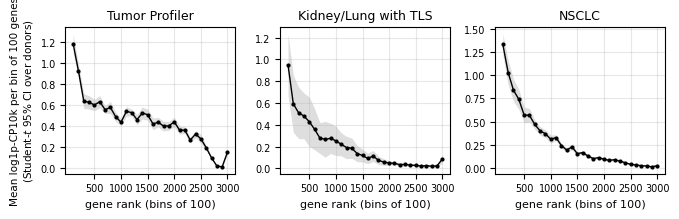


=== mean expression per bin of 100 genes, log1p-CP10k [95% donor CI on the mean] ===
dataset                       10x_TuPro                      TLS              LUNG_CANCER
bin rank_range                                                                           
1   1-100       1.1834 [1.0905, 1.2763]  0.9514 [0.6693, 1.2335]  1.3318 [1.2190, 1.4447]
2   101-200     0.9239 [0.8622, 0.9856]  0.5930 [0.3321, 0.8540]  1.0288 [0.8950, 1.1626]
3   201-300     0.6365 [0.5649, 0.7081]  0.5101 [0.2738, 0.7465]  0.8386 [0.7193, 0.9578]
4   301-400     0.6246 [0.5620, 0.6873]  0.4815 [0.2721, 0.6909]  0.7412 [0.6335, 0.8488]
5   401-500     0.6003 [0.5454, 0.6551]  0.4288 [0.2019, 0.6557]  0.5720 [0.4875, 0.6565]
6   501-600     0.6312 [0.5736, 0.6889]  0.3597 [0.1715, 0.5479]  0.5680 [0.4946, 0.6415]
7   601-700     0.5556 [0.5202, 0.5910]  0.2791 [0.1370, 0.4211]  0.4702 [0.4192, 0.5212]
8   701-800     0.5763 [0.5186, 0.6341]  0.2670 [0.1026, 0.4313]  0.4008 [0.3553, 0.4463]
9   801-900   

In [18]:
# =====================================================================================================
# FIGURE fig:expression_bins -- mean expression per BIN of 100 genes, 1 row x 3 datasets.
# Second separate figure, complement of the previous one: same data, same ranking, DIFFERENT
# OPPOSITE.
#
# Cumulative (figure above)  : mean of the top n genes -> each point contains all the
#                              previous ones, so the curve is smoothed and can only drift
#                              slowly; it is the number cited at a given cutoff.
# Per bin (this figure)      : mean of the genes ranked 1-100, 101-200, ... 2901-3000 -> 30 points
#                              DISJOINT. It is the derivative of the cumulative: it shows WHERE
#                              along the ranking the expression level drops off, which the
#                              cumulative hides by construction.
#
# The rank axis is a PREDICTABILITY axis (the genes are ranked by cross-model Pearson
# averaged over the donors), not an expression axis: the question asked is "does expression follow
# predictability?", and a flat curve would answer NO.
#
# Everything else is identical to the previous figure and deliberately reused from it:
# shared_gene_order (the same ranking, so both figures talk about the same genes),
# EXPR_DONOR_BY_DS (log1p-CP10k per (gene, donor)), and the band = 95% Student-t on the K points
# per donor, DESCRIPTIVE (variability of the expression level across patients), never a
# generalization claim about a model.
# =====================================================================================================
from scipy.stats import spearmanr

BIN = 100          # slice size; 3000 genes / 100 = 30 points

bin_rows = []
for ds in DATASETS:
    order = shared_gene_order(ds)                  # SAME ranking as the previous figure
    mat = EXPR_DONOR_BY_DS[ds].reindex(order)      # (gene x donor), log1p-CP10k
    n_bins = int(np.ceil(len(order) / BIN))
    for b in range(n_bins):
        block = mat.iloc[b * BIN:(b + 1) * BIN]
        st = donor_lopo_stats(block.mean(axis=0, skipna=True).to_dict())   # genes -> K points
        bin_rows.append(dict(dataset=ds, bin=b + 1, rank_lo=b * BIN + 1,
                             rank_hi=min((b + 1) * BIN, len(order)), n_genes=len(block),
                             K=st["K"], mean=st["mean"], sd=st["sd"], sem=st["sem"],
                             lo=st["ci95_mean"][0], hi=st["ci95_mean"][1]))
expr_bins = pd.DataFrame(bin_rows)

# A final incomplete bin (panel not a multiple of BIN) would carry fewer genes than the others,
# hence a noisier mean with a wider band: flag it rather than dropping it silently.
for ds in DATASETS:
    last = expr_bins[expr_bins["dataset"] == ds].iloc[-1]
    if last["n_genes"] != BIN:
        print(f"(!) {ds} : last bin incomplete ({int(last['n_genes'])} genes instead of {BIN})")

fig, axes = plt.subplots(1, len(DATASETS), figsize=(6.9, 2.3), squeeze=False)
for j, ds in enumerate(DATASETS):
    ax = axes[0, j]
    cur = expr_bins[expr_bins["dataset"] == ds].sort_values("bin")
    x = np.arange(len(cur))
    ax.fill_between(x, cur["lo"], cur["hi"], color="black", alpha=0.13, linewidth=0)
    ax.plot(x, cur["mean"], "-o", ms=2.0, lw=1.0, color="black")
    ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
    # 30 points: one label out of five, carrying the TOP rank of the bin (500, 1000, ... 3000),
    # otherwise the axis is unreadable at the printed size.
    ticks = np.arange(4, len(cur), 5)
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(int(cur["rank_hi"].iloc[t])) for t in ticks], fontsize=6.5)
    ax.set_xlabel(f"gene rank (bins of {BIN})", fontsize=8)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=7)
axes[0, 0].set_ylabel(f"Mean log1p-CP10k per bin of {BIN} genes\n(Student-$t$ 95% CI over donors)",
                      fontsize=7.5)
plt.tight_layout()

for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_expression_bins_pr_classic3.{ext}", dpi=300, bbox_inches="tight")
print("\nwritten:", "fig_expression_bins_pr_classic3.pdf")
plt.show()

# Printed twin of the figure: rows = bin (start-end rank), columns = dataset.
print(f"\n=== mean expression per bin of {BIN} genes, log1p-CP10k "
      "[95% donor CI on the mean] ===")
tbl = expr_bins.assign(
    rank_range=[f"{int(r.rank_lo)}-{int(r.rank_hi)}" for r in expr_bins.itertuples()],
    c=[f"{r.mean:.4f} [{r.lo:.4f}, {r.hi:.4f}]" for r in expr_bins.itertuples()])
print(tbl.pivot_table(index=["bin", "rank_range"], columns="dataset", values="c",
                      aggfunc="first").reindex(columns=DATASETS).to_string())

# Two numeric readings of the slope, to cite rather than "the curve goes down":
#   first/last bin ratio = the total amplitude along the ranking;
#   Spearman(bin rank, expression) = the monotonicity, over the 30 plotted points (hence a
#   summary of the FIGURE, not a per-gene test -- the per-gene link is the scatter in section 7 of
#   the canal1 notebook, on individual genes).
print("\n=== slope along the predictability ranking ===")
for ds in DATASETS:
    cur = expr_bins[expr_bins["dataset"] == ds].sort_values("bin")
    a, b = cur.iloc[0], cur.iloc[-1]
    rho, pval = spearmanr(cur["bin"], cur["mean"])
    print(f"{DATASET_LABELS.get(ds, ds):<22s} slice 1 {a['mean']:.4f}  ->  "
          f"slice {int(b['bin'])} {b['mean']:.4f}   ratio {a['mean'] / b['mean']:.2f}x   "
          f"Spearman(rank, expr) = {rho:+.3f} (p={pval:.1e}, N={len(cur)} slices)")

=== spots per donor (what makes the COUNT donor-dependent) ===
  10x_TuPro    K=7  min 7,561 / median 8,904 / max 18,483   (max/min 2.4x)
  TLS          K=6  min 2,017 / median 3,312 / max 4,361   (max/min 2.2x)
  LUNG_CANCER  K=8  min 4,481 / median 8,844 / max 11,363   (max/min 2.5x)

written: fig_detection_topn_pr_classic3.pdf


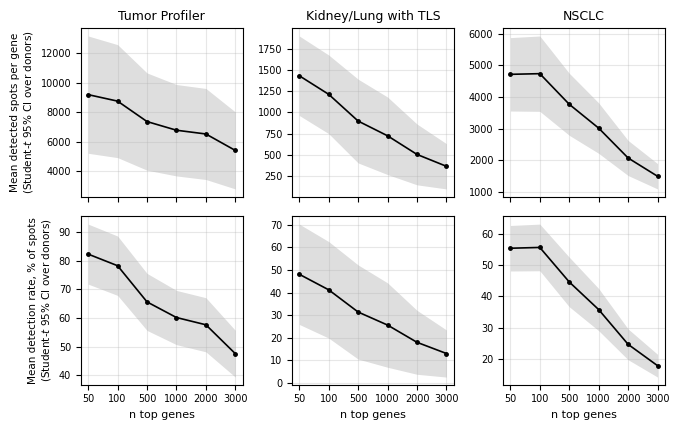


=== mean number of detected spots per gene, cumulative over the top n genes [95% donor CI on the mean] ===
n                                50                        100                       500                      1000                     2000                     3000
dataset                                                                                                                                                             
10x_TuPro    9193.9 [5199.5, 13188.4]  8751.0 [4903.7, 12598.4]  7359.6 [4047.7, 10671.5]  6769.9 [3656.1, 9883.7]  6513.9 [3413.2, 9614.6]  5392.9 [2770.8, 8014.9]
TLS            1431.0 [964.6, 1897.3]    1212.9 [751.6, 1674.2]     899.2 [407.9, 1390.5]    726.3 [271.6, 1181.1]     507.8 [151.1, 864.5]     368.5 [102.9, 634.2]
LUNG_CANCER   4713.4 [3553.4, 5873.5]   4734.4 [3543.8, 5925.0]   3767.1 [2786.5, 4747.6]  3013.7 [2216.6, 3810.8]  2070.4 [1515.9, 2624.8]  1492.7 [1092.0, 1893.5]
   inter-donor sd / sem (K donors):
n                     50       

In [19]:
# =====================================================================================================
# FIGURE (new, ADDITIVE) -- number of DETECTED entries along the same top-n axis as the expression
# figure. It replaces nothing: fig_expression_topn_pr_classic3 and
# fig_expression_bins_pr_classic3 stay as they are, this cell writes under a file name
# DISTINCT (fig_detection_topn_pr_classic3).
#
# "detected entry" = a (spot, gene) pair whose count is not zero. Nothing to do with the word
# "detected" in the deltas cell above (there: an effect whose CI excludes 0) -- here it is a
# property of the DATA: is the gene seen in this spot. The per-donor parquet carries pct_zeros
# (fraction of the donor's spots where the gene is zero) and n_spots, so
#     detected spots of gene g in donor d = n_spots[d] * (1 - pct_zeros[d, g]).
#
# TWO rows, because the answer depends on the scale chosen:
#   row 1 = mean NUMBER of detected spots per gene (what is asked). Read with care: the
#           donors do not have the same number of spots, so the between-donor spread of that count
#           mixes "this gene is seen more often" and "this donor has more spots" -- the band is
#           wide there for a partly non-biological reason (the sizes are printed below).
#   row 2 = detection RATE (% of the donor's spots), the version without that size confound;
#           it is the one to cite for "are the best predicted genes also the most detected?".
#
# Everything else is taken identically from the expression figure: SAME shared_gene_order (so
# "n = 500" designates the same 500 genes on the three figures), same per-donor parquet, same
# 95% Student-t band on the K per-donor points -- DESCRIPTIVE (variability across patients), never a
# claim about a model's generalization. Depends on the cells above for expr_donor_df,
# shared_gene_order, donor_lopo_stats, DATASET_LABELS, FIG_DIR and NS.
# =====================================================================================================

# (gene x donor) for both scales, from the SAME already-loaded parquet (no re-read).
DETECT_DONOR_BY_DS, RATE_DONOR_BY_DS = {}, {}
for ds, g in expr_donor_df.groupby("dataset"):
    g = g.assign(n_detected=g["n_spots"] * (1.0 - g["pct_zeros"]),
                 detect_pct=100.0 * (1.0 - g["pct_zeros"]))
    DETECT_DONOR_BY_DS[ds] = g.pivot_table(index="gene", columns="donor", values="n_detected")
    RATE_DONOR_BY_DS[ds] = g.pivot_table(index="gene", columns="donor", values="detect_pct")

# The size confound announced above, quantified: without this max/min ratio we cannot tell whether
# the row 1 band is biological or only geometric.
print("=== spots per donor (what makes the COUNT donor-dependent) ===")
for ds in DATASETS:
    sz = expr_donor_df[expr_donor_df["dataset"] == ds].groupby("donor")["n_spots"].first()
    print(f"  {ds:<12s} K={len(sz)}  min {int(sz.min()):,} / median {int(sz.median()):,} / "
          f"max {int(sz.max()):,}   (max/min {sz.max() / sz.min():.1f}x)")

QUANTITIES = [
    dict(name="count", by_ds=DETECT_DONOR_BY_DS, fmt="{:.1f}",
         ylab="Mean detected spots per gene\n(Student-$t$ 95% CI over donors)",
         header="mean number of detected spots per gene"),
    dict(name="pct", by_ds=RATE_DONOR_BY_DS, fmt="{:.2f}",
         ylab="Mean detection rate, % of spots\n(Student-$t$ 95% CI over donors)",
         header="mean detection rate, % of the donor's spots"),
]

rows = []
for ds in DATASETS:
    order = shared_gene_order(ds)                  # SAME ranking as the two previous figures
    for q in QUANTITIES:
        mat = q["by_ds"][ds].reindex(order)        # (gene x donor), in the curve order
        n_missing = int(mat.isna().all(axis=1).sum())
        if n_missing and q["name"] == "count":
            print(f"(!) {ds} : {n_missing}/{len(order)} panel genes missing from the expression parquet")
        for n in sorted({len(order) if k is None else min(int(k), len(order)) for k in NS}):
            st = donor_lopo_stats(mat.iloc[:n].mean(axis=0, skipna=True).to_dict())  # genes -> K points
            rows.append(dict(dataset=ds, quantity=q["name"], n=int(n), K=st["K"], mean=st["mean"],
                             sd=st["sd"], sem=st["sem"], lo=st["ci95_mean"][0], hi=st["ci95_mean"][1],
                             pi_lo=st["pi95_new_donor"][0], pi_hi=st["pi95_new_donor"][1]))
detect_curves = pd.DataFrame(rows)

# y axes INDEPENDENT from one panel to the next, as in the figures above: the three datasets have
# neither the same number of spots nor the same detection rate, a common axis would flatten two of three.
fig, axes = plt.subplots(len(QUANTITIES), len(DATASETS), figsize=(6.9, 4.4), squeeze=False)
for i, q in enumerate(QUANTITIES):
    last_row = (i == len(QUANTITIES) - 1)
    for j, ds in enumerate(DATASETS):
        ax = axes[i, j]
        cur = detect_curves[(detect_curves["dataset"] == ds)
                            & (detect_curves["quantity"] == q["name"])].sort_values("n")
        x = np.arange(len(cur))
        ax.fill_between(x, cur["lo"], cur["hi"], color="black", alpha=0.13, linewidth=0)
        ax.plot(x, cur["mean"], "-o", ms=2.5, lw=1.2, color="black")
        if i == 0:
            ax.set_title(DATASET_LABELS.get(ds, ds), fontsize=9)
        ax.set_xticks(x)
        ax.set_xticklabels([str(int(n)) for n in cur["n"]] if last_row else [""] * len(x), fontsize=6.5)
        if last_row:
            ax.set_xlabel("n top genes", fontsize=8)
        ax.grid(alpha=0.3)
        ax.tick_params(labelsize=7)
    axes[i, 0].set_ylabel(q["ylab"], fontsize=7.5)
plt.tight_layout()

# DISTINCT filename per run, so re-running one notebook can never overwrite another run's figure.
for ext in ("pdf", "png"):
    fig.savefig(FIG_DIR / f"fig_detection_topn_pr_classic3.{ext}", dpi=300, bbox_inches="tight")
print("\nwritten:", "fig_detection_topn_pr_classic3.pdf")
plt.show()

# The printed twins of the figure: a PNG is not a readable result, the plotted numbers must
# be so too.
for q in QUANTITIES:
    cur = detect_curves[detect_curves["quantity"] == q["name"]]
    print(f"\n=== {q['header']}, cumulative over the top n genes "
          "[95% donor CI on the mean] ===")
    cells = [f"{q['fmt'].format(r.mean)} [{q['fmt'].format(r.lo)}, {q['fmt'].format(r.hi)}]"
             for r in cur.itertuples()]
    print(cur.assign(c=cells).pivot_table(index="dataset", columns="n", values="c",
                                          aggfunc="first").reindex(DATASETS).to_string())
    print("   inter-donor sd / sem (K donors):")
    w = [f"{q['fmt'].format(r.sd)}/{q['fmt'].format(r.sem)}" for r in cur.itertuples()]
    print(cur.assign(c=w).pivot_table(index="dataset", columns="n", values="c",
                                      aggfunc="first").reindex(DATASETS).to_string())

# Direct reading, same form as for expression. The n axis is a PREDICTABILITY axis (the
# ranking is done on Pearson), not a detection axis: a ratio > 1 says the best predicted
# genes are also the most often detected, a ratio = 1 would say the two are decoupled.
print("\n=== are the best predicted genes also the most detected ? "
      "(smallest n vs full panel) ===")
for q in QUANTITIES:
    print(f"  -- {q['header']}")
    for ds in DATASETS:
        cur = detect_curves[(detect_curves["dataset"] == ds)
                            & (detect_curves["quantity"] == q["name"])].sort_values("n")
        a, b = cur.iloc[0], cur.iloc[-1]
        print(f"     {DATASET_LABELS.get(ds, ds):<22s} n={int(a['n']):<5d} {q['fmt'].format(a['mean'])}"
              f"   ->   n={int(b['n']):<5d} {q['fmt'].format(b['mean'])}"
              f"   ratio {a['mean'] / b['mean']:.2f}x")